       IMAGE PIXEL MANIPULATOR USING NUMPY

STEP 1: IMAGE CREATION
Image shape: (200, 200, 3)
Image data type: uint8
Image memory: 120000 bytes
White patch shape: (20, 20, 3)
Gray pixel value: [128 128 128]

STEP 2: DRAWING
Colored blocks and stripes created successfully.

STEP 3: CROPPING, FLIPPING AND CHANNELS
Original image shape: (200, 200, 3)
Cropped image shape: (110, 70, 3)
Vertical flip shape: (200, 200, 3)
Horizontal flip shape: (200, 200, 3)
Combined flip shape: (200, 200, 3)
Red channel shape: (200, 200)
Green channel shape: (200, 200)
Blue channel shape: (200, 200)

STEP 4: BRIGHTNESS AND BOOLEAN MASKING
Brightened image type: uint8
Darkened image type: uint8
Mask data type: bool
Number of bright pixels: 5400

STEP 5: MEMORY COMPARISON
uint8 memory: 120000 bytes
float64 memory: 960000 bytes
uint8 memory: 117.1875 KB
float64 memory: 937.5 KB
Memory ratio: 8 times
uint8 data type: uint8
float64 data type: float64


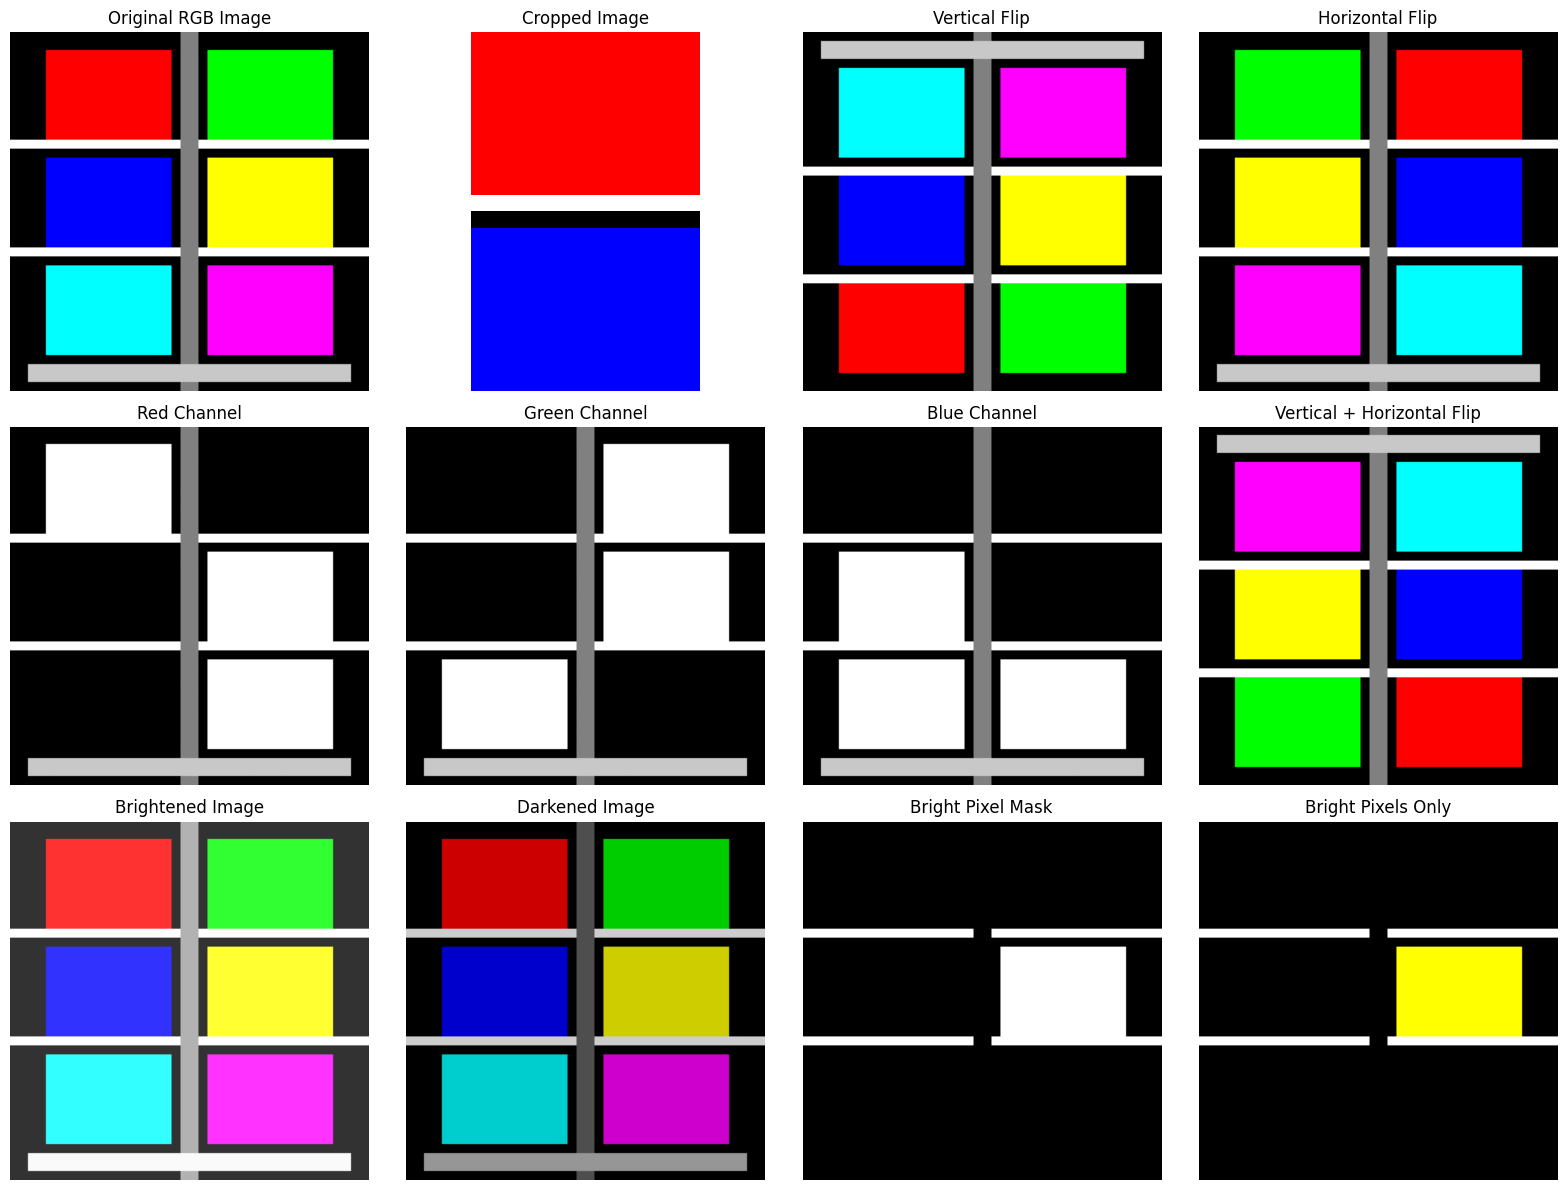


          PROJECT COMPLETED SUCCESSFULLY!
Image dimensions: 200 x 200 x 3
Operations performed:
1. Image creation using NumPy
2. Drawing colored blocks and stripes
3. Cropping and image flipping
4. RGB channel extraction
5. Brightness adjustment
6. Boolean masking
7. Memory comparison: uint8 vs float64
8. Image visualization using Matplotlib


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("=" * 60)
print("       IMAGE PIXEL MANIPULATOR USING NUMPY")
print("=" * 60)

img = np.zeros((200, 200, 3), dtype=np.uint8)

print("\nSTEP 1: IMAGE CREATION")
print("Image shape:", img.shape)
print("Image data type:", img.dtype)
print("Image memory:", img.nbytes, "bytes")

white_patch = np.ones((20, 20, 3), dtype=np.uint8) * 255

gray_patch = np.full((20, 20, 3), 128, dtype=np.uint8)

print("White patch shape:", white_patch.shape)
print("Gray pixel value:", gray_patch[0, 0])

img[10:60, 20:90, :] = [255, 0, 0]


img[10:60, 110:180, :] = [0, 255, 0]


img[70:120, 20:90, :] = [0, 0, 255]


img[70:120, 110:180, :] = [255, 255, 0]


img[130:180, 20:90, :] = [0, 255, 255]


img[130:180, 110:180, :] = [255, 0, 255]


img[60:65, :, :] = [255, 255, 255]
img[120:125, :, :] = [255, 255, 255]


img[:, 95:105, :] = [128, 128, 128]


img[185:195, 10:190, :] = np.full(
    (10, 180, 3), 200, dtype=np.uint8
)

print("\nSTEP 2: DRAWING")
print("Colored blocks and stripes created successfully.")


cropped_img = img[10:120, 20:90, :].copy()


vertical_flip = img[::-1, :, :]

horizontal_flip = img[:, ::-1, :]


both_flip = img[::-1, ::-1, :]


red_channel = img[:, :, 0]
green_channel = img[:, :, 1]
blue_channel = img[:, :, 2]

print("\nSTEP 3: CROPPING, FLIPPING AND CHANNELS")
print("Original image shape:", img.shape)
print("Cropped image shape:", cropped_img.shape)
print("Vertical flip shape:", vertical_flip.shape)
print("Horizontal flip shape:", horizontal_flip.shape)
print("Combined flip shape:", both_flip.shape)
print("Red channel shape:", red_channel.shape)
print("Green channel shape:", green_channel.shape)
print("Blue channel shape:", blue_channel.shape)


img_float = img.astype(np.float32)


bright_img = np.clip(
    img_float + 50, 0, 255
).astype(np.uint8)


dark_img = np.clip(
    img_float - 50, 0, 255
).astype(np.uint8)

brightness = (
    0.299 * img_float[:, :, 0]
    + 0.587 * img_float[:, :, 1]
    + 0.114 * img_float[:, :, 2]
)


bright_mask = brightness > 200


bright_pixel_count = np.count_nonzero(bright_mask)

bright_pixels_only = np.zeros_like(img)
bright_pixels_only[bright_mask] = img[bright_mask]

print("\nSTEP 4: BRIGHTNESS AND BOOLEAN MASKING")
print("Brightened image type:", bright_img.dtype)
print("Darkened image type:", dark_img.dtype)
print("Mask data type:", bright_mask.dtype)
print("Number of bright pixels:", bright_pixel_count)

img_float64 = img.astype(np.float64)

uint8_memory = img.nbytes
float64_memory = img_float64.nbytes

print("\nSTEP 5: MEMORY COMPARISON")
print("uint8 memory:", uint8_memory, "bytes")
print("float64 memory:", float64_memory, "bytes")
print("uint8 memory:", uint8_memory / 1024, "KB")
print("float64 memory:", float64_memory / 1024, "KB")
print("Memory ratio:", float64_memory // uint8_memory, "times")

print("uint8 data type:", img.dtype)
print("float64 data type:", img_float64.dtype)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

axes[0, 0].imshow(img)
axes[0, 0].set_title("Original RGB Image")

axes[0, 1].imshow(cropped_img)
axes[0, 1].set_title("Cropped Image")

axes[0, 2].imshow(vertical_flip)
axes[0, 2].set_title("Vertical Flip")

axes[0, 3].imshow(horizontal_flip)
axes[0, 3].set_title("Horizontal Flip")


axes[1, 0].imshow(
    red_channel, cmap="gray", vmin=0, vmax=255
)
axes[1, 0].set_title("Red Channel")

axes[1, 1].imshow(
    green_channel, cmap="gray", vmin=0, vmax=255
)
axes[1, 1].set_title("Green Channel")

axes[1, 2].imshow(
    blue_channel, cmap="gray", vmin=0, vmax=255
)
axes[1, 2].set_title("Blue Channel")

axes[1, 3].imshow(both_flip)
axes[1, 3].set_title("Vertical + Horizontal Flip")


axes[2, 0].imshow(bright_img)
axes[2, 0].set_title("Brightened Image")

axes[2, 1].imshow(dark_img)
axes[2, 1].set_title("Darkened Image")

axes[2, 2].imshow(
    bright_mask, cmap="gray", vmin=0, vmax=1
)
axes[2, 2].set_title("Bright Pixel Mask")

axes[2, 3].imshow(bright_pixels_only)
axes[2, 3].set_title("Bright Pixels Only")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("          PROJECT COMPLETED SUCCESSFULLY!")
print("=" * 60)

print("Image dimensions: 200 x 200 x 3")
print("Operations performed:")
print("1. Image creation using NumPy")
print("2. Drawing colored blocks and stripes")
print("3. Cropping and image flipping")
print("4. RGB channel extraction")
print("5. Brightness adjustment")
print("6. Boolean masking")
print("7. Memory comparison: uint8 vs float64")
print("8. Image visualization using Matplotlib")
